# Phishing URL Model Evaluation


In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import xgboost as xgb
import shap
import joblib

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report, roc_curve
)

print('All libraries imported successfully.')

All libraries imported successfully.


In [5]:
df = pd.read_csv('phishing.csv')

print('Dataset loaded successfully.')
print('Dataset shape:', df.shape)
print('\nFirst 5 rows:')
display(df.head())

Dataset loaded successfully.
Dataset shape: (235795, 56)

First 5 rows:


,FILENAME,URL,URLLength,Domain,DomainLength,IsDomainIP,TLD,URLSimilarityIndex,CharContinuationRate,TLDLegitimateProb,...,Pay,Crypto,HasCopyrightInfo,NoOfImage,NoOfCSS,NoOfJS,NoOfSelfRef,NoOfEmptyRef,NoOfExternalRef,label
0,521848.txt,https://www.southbankmosaics.com,31,www.southbankmosaics.com,24,0,com,100.0,1.000000,0.522907,...,0,0,1,34,20,28,119,0,124,1
1,31372.txt,https://www.uni-mainz.de,23,www.uni-mainz.de,16,0,de,100.0,0.666667,0.032650,...,0,0,1,50,9,8,39,0,217,1
2,597387.txt,https://www.voicefmradio.co.uk,29,www.voicefmradio.co.uk,22,0,uk,100.0,0.866667,0.028555,...,0,0,1,10,2,7,42,2,5,1
3,554095.txt,https://www.sfnmjournal.com,26,www.sfnmjournal.com,19,0,com,100.0,1.000000,0.522907,...,1,1,1,3,27,15,22,1,31,1
4,151578.txt,https://www.rewildingargentina.org,33,www.rewildingargentina.org,26,0,org,100.0,1.000000,0.079963,...,1,0,1,244,15,34,72,1,85,1


In [6]:
df.columns = df.columns.str.lower().str.strip()

if 'url' not in df.columns:
    raise ValueError('URL column not found.')
if 'label' not in df.columns:
    raise ValueError('Label column not found.')

df = df.dropna(subset=['url', 'label'])
df = df.drop_duplicates(subset=['url'])

print('Rows after cleaning:', len(df))
print('Unique labels:', df['label'].unique())

Rows after cleaning: 235370
Unique labels: [1 0]


In [7]:
print('Original label distribution:')
print(df['label'].value_counts())

# Uses the dataset convention: 0 = legitimate, 1 = phishing.
# Verify the meaning of your dataset labels before reporting results.
df['target'] = df['label'].astype(int)

print('\nTarget distribution:')
print(df['target'].value_counts())

Original label distribution:
label
1    134850
0    100520
Name: count, dtype: int64

Target distribution:
target
1    134850
0    100520
Name: count, dtype: int64


In [8]:
import re
import math
from urllib.parse import urlparse

def extract_features(url):
    url = str(url)
    try:
        parsed = urlparse(url)
    except Exception:
        parsed = urlparse('')

    domain = parsed.netloc.split(':')[0]
    url_length = len(url)
    domain_length = len(domain)
    digits = sum(c.isdigit() for c in url)
    letters = sum(c.isalpha() for c in url)
    special_chars = sum(not c.isalnum() for c in url)

    parts = domain.split('.')
    no_of_subdomain = max(len(parts) - 2, 0)
    is_domain_ip = int(bool(re.match(r'^(\d{1,3}\.){3}\d{1,3}$', domain)))
    is_https = int(parsed.scheme.lower() == 'https')

    has_obfuscation = int('%' in url or '\\x' in url.lower() or '@' in url)
    no_of_obfuscated_char = url.count('%') + url.lower().count('\\x')
    no_of_equals = url.count('=')
    no_of_qmark = url.count('?')
    no_of_ampersand = url.count('&')
    no_of_other_special = sum(url.count(c) for c in ['-', '_', '@', '#', '%', ';', ':'])

    letter_ratio = letters / url_length if url_length else 0
    digit_ratio = digits / url_length if url_length else 0
    special_ratio = special_chars / url_length if url_length else 0
    obfuscation_ratio = no_of_obfuscated_char / url_length if url_length else 0

    continuation_rate = 0
    if url_length > 1:
        continuation_rate = sum(
            1 for i in range(1, url_length)
            if url[i].isalnum() and url[i-1].isalnum()
        ) / (url_length - 1)

    tld = parts[-1].lower() if len(parts) >= 2 else ''
    suspicious_words = [
        'login', 'signin', 'verify', 'verification', 'account',
        'secure', 'update', 'password', 'bank', 'payment',
        'free', 'bonus', 'crypto', 'wallet', 'confirm'
    ]
    url_lower = url.lower()
    suspicious_keyword_count = sum(word in url_lower for word in suspicious_words)

    def entropy(text):
        if not text:
            return 0
        probabilities = [text.count(c) / len(text) for c in set(text)]
        return -sum(p * math.log2(p) for p in probabilities if p > 0)

    return {
        'url_length': url_length,
        'domain_length': domain_length,
        'is_domain_ip': is_domain_ip,
        'no_of_subdomain': no_of_subdomain,
        'has_obfuscation': has_obfuscation,
        'no_of_obfuscated_char': no_of_obfuscated_char,
        'obfuscation_ratio': obfuscation_ratio,
        'no_of_letters': letters,
        'letter_ratio': letter_ratio,
        'no_of_digits': digits,
        'digit_ratio': digit_ratio,
        'no_of_equals': no_of_equals,
        'no_of_qmark': no_of_qmark,
        'no_of_ampersand': no_of_ampersand,
        'no_of_other_special_chars': no_of_other_special,
        'special_char_ratio': special_ratio,
        'is_https': is_https,
        'no_of_slashes': url.count('/'),
        'no_of_dots': url.count('.'),
        'no_of_hyphens': url.count('-'),
        'continuation_rate': continuation_rate,
        'tld_length': len(tld),
        'suspicious_keyword_count': suspicious_keyword_count,
        'domain_entropy': entropy(domain),
        'url_entropy': entropy(url)
    }

print('Feature extraction function created successfully.')

Feature extraction function created successfully.


In [9]:
test_url = df['url'].iloc[0]
print('Test URL:', test_url)
print('\nExtracted features:')
print(extract_features(test_url))

Test URL: https://www.southbankmosaics.com

Extracted features:
{'url_length': 32, 'domain_length': 24, 'is_domain_ip': 0, 'no_of_subdomain': 1, 'has_obfuscation': 0, 'no_of_obfuscated_char': 0, 'obfuscation_ratio': 0.0, 'no_of_letters': 27, 'letter_ratio': 0.84375, 'no_of_digits': 0, 'digit_ratio': 0.0, 'no_of_equals': 0, 'no_of_qmark': 0, 'no_of_ampersand': 0, 'no_of_other_special_chars': 1, 'special_char_ratio': 0.15625, 'is_https': 1, 'no_of_slashes': 2, 'no_of_dots': 2, 'no_of_hyphens': 0, 'continuation_rate': 0.7419354838709677, 'tld_length': 3, 'suspicious_keyword_count': 1, 'domain_entropy': 3.6572682296173893, 'url_entropy': 3.9292292966721747}


In [10]:
print('Extracting URL features...')

X = pd.DataFrame([extract_features(url) for url in df['url']])
y = df['target']

X = X.replace([np.inf, -np.inf], np.nan).fillna(0)

print('Feature extraction completed.')
print('X shape:', X.shape)
print('y shape:', y.shape)

Extracting URL features...
Feature extraction completed.
X shape: (235370, 25)
y shape: (235370,)


In [11]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print('X_train:', X_train.shape)
print('X_test :', X_test.shape)
print('y_train:', y_train.shape)
print('y_test :', y_test.shape)

X_train: (188296, 25)
X_test : (47074, 25)
y_train: (188296,)
y_test : (47074,)


In [12]:
model = xgb.XGBClassifier(
    n_estimators=100,
    max_depth=6,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    eval_metric='logloss',
    random_state=42,
    n_jobs=-1
)

print('XGBoost model created successfully.')

XGBoost model created successfully.


In [13]:
print('Training XGBoost model...')
model.fit(X_train, y_train)
print('Model training completed successfully.')

Training XGBoost model...
Model training completed successfully.


In [14]:
y_pred = model.predict(X_test)
y_proba = model.predict_proba(X_test)[:, 1]

print('Predictions generated successfully.')

Predictions generated successfully.


In [15]:
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)
roc_auc = roc_auc_score(y_test, y_proba)

print('=' * 60)
print('MODEL PERFORMANCE')
print('=' * 60)
print(f'Accuracy  : {accuracy:.4f} ({accuracy * 100:.2f}%)')
print(f'Precision : {precision:.4f}')
print(f'Recall    : {recall:.4f}')
print(f'F1 Score  : {f1:.4f}')
print(f'ROC-AUC   : {roc_auc:.4f}')
print('=' * 60)

MODEL PERFORMANCE
Accuracy  : 0.9961 (99.61%)
Precision : 0.9938
Recall    : 0.9995
F1 Score  : 0.9966
ROC-AUC   : 0.9981


Confusion Matrix:
[[19935   169]
 [   14 26956]]


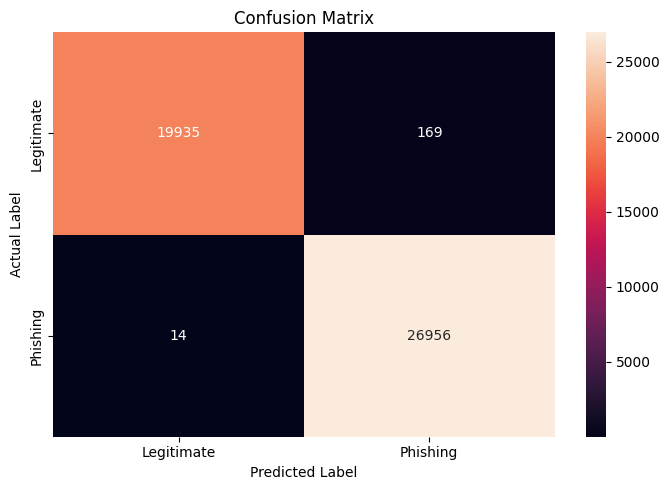

In [16]:
cm = confusion_matrix(y_test, y_pred)
print('Confusion Matrix:')
print(cm)

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    xticklabels=['Legitimate', 'Phishing'],
    yticklabels=['Legitimate', 'Phishing']
)
plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')
plt.title('Confusion Matrix')
plt.tight_layout()
plt.show()

In [17]:
print(classification_report(
    y_test,
    y_pred,
    target_names=['Legitimate', 'Phishing'],
    zero_division=0
))

              precision    recall  f1-score   support

  Legitimate       1.00      0.99      1.00     20104
    Phishing       0.99      1.00      1.00     26970

    accuracy                           1.00     47074
   macro avg       1.00      1.00      1.00     47074
weighted avg       1.00      1.00      1.00     47074



In [18]:
report = classification_report(
    y_test, y_pred,
    target_names=['Legitimate', 'Phishing'],
    output_dict=True,
    zero_division=0
)

report_df = pd.DataFrame(report).transpose()
display(report_df.round(4))

,precision,recall,f1-score,support
Legitimate,0.9993,0.9916,0.9954,20104.0000
Phishing,0.9938,0.9995,0.9966,26970.0000
accuracy,0.9961,0.9961,0.9961,0.9961
macro avg,0.9965,0.9955,0.9960,47074.0000
weighted avg,0.9961,0.9961,0.9961,47074.0000


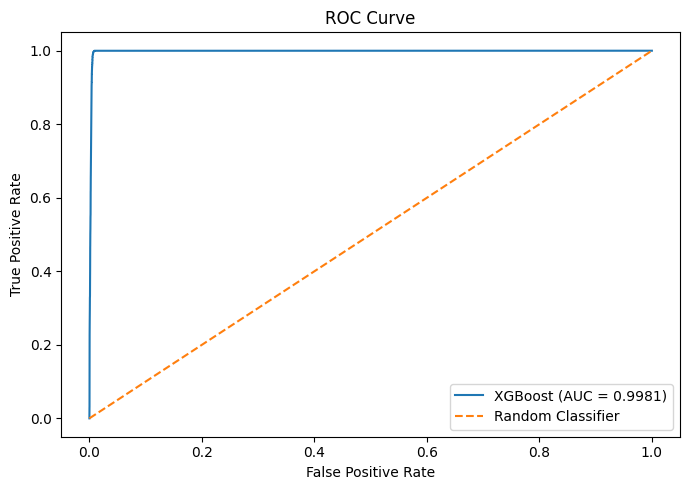

In [19]:
fpr, tpr, _ = roc_curve(y_test, y_proba)

plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, label=f'XGBoost (AUC = {roc_auc:.4f})')
plt.plot([0, 1], [0, 1], linestyle='--', label='Random Classifier')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend()
plt.tight_layout()
plt.show()

In [20]:
importance = pd.DataFrame({
    'Feature': X.columns,
    'Importance': model.feature_importances_
}).sort_values('Importance', ascending=False)

display(importance.head(15))

,Feature,Importance
16,is_https,0.475692
17,no_of_slashes,0.439255
9,no_of_digits,0.034807
18,no_of_dots,0.009151
0,url_length,0.007320
3,no_of_subdomain,0.007064
1,domain_length,0.005583
21,tld_length,0.003183
8,letter_ratio,0.002989
10,digit_ratio,0.002939


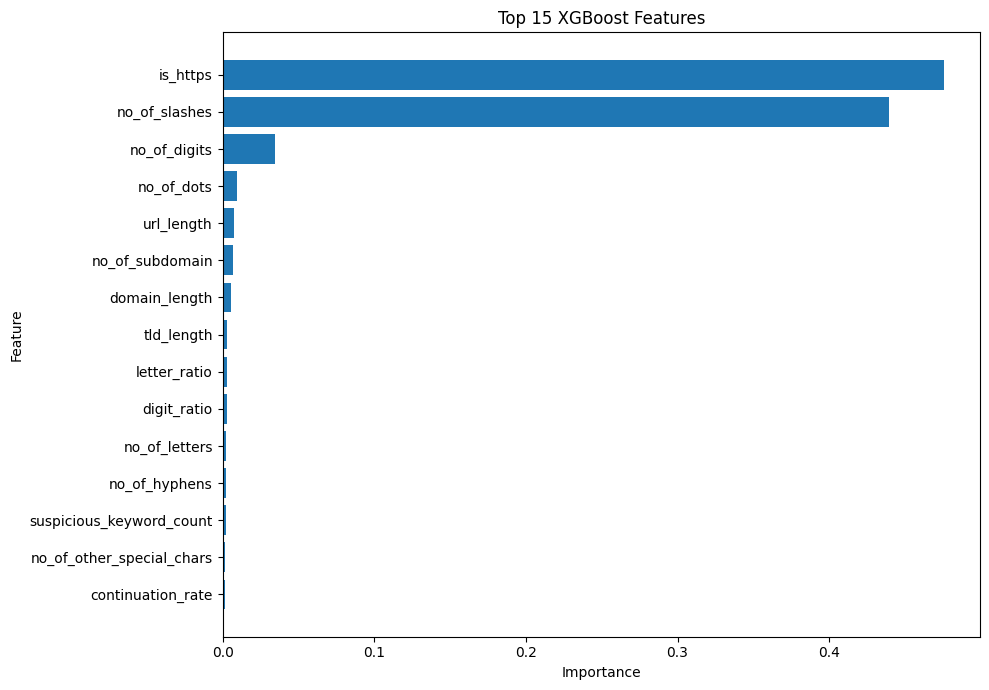

In [21]:
top_features = importance.head(15)

plt.figure(figsize=(10, 7))
plt.barh(top_features['Feature'][::-1], top_features['Importance'][::-1])
plt.xlabel('Importance')
plt.ylabel('Feature')
plt.title('Top 15 XGBoost Features')
plt.tight_layout()
plt.show()

In [22]:
print('Creating SHAP explainer...')
explainer = shap.TreeExplainer(model)
print('SHAP explainer created successfully.')

Creating SHAP explainer...
SHAP explainer created successfully.


In [23]:
sample_size = min(1000, len(X_test))
X_shap = X_test.sample(n=sample_size, random_state=42)

print('SHAP sample shape:', X_shap.shape)
shap_values = explainer.shap_values(X_shap)
print('SHAP values calculated.')

SHAP sample shape: (1000, 25)
SHAP values calculated.


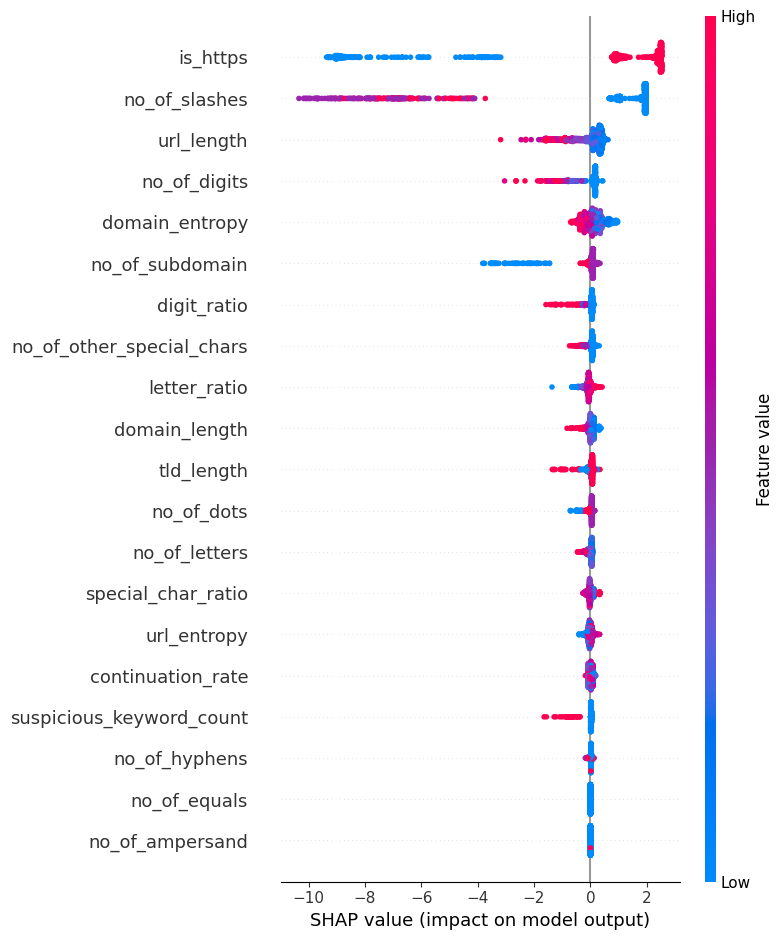

In [24]:
plt.figure()
shap.summary_plot(shap_values, X_shap, show=False)
plt.tight_layout()
plt.show()

In [25]:
joblib.dump(model, 'xgboost_model.pkl')
joblib.dump(explainer, 'shap_explainer.pkl')
joblib.dump(list(X.columns), 'feature_names.pkl')

print('Saved: xgboost_model.pkl')
print('Saved: shap_explainer.pkl')
print('Saved: feature_names.pkl')

Saved: xgboost_model.pkl
Saved: shap_explainer.pkl
Saved: feature_names.pkl


In [26]:
loaded_model = joblib.load('xgboost_model.pkl')
feature_names = joblib.load('feature_names.pkl')

test_url = 'https://www.google.com'
test_features = pd.DataFrame([extract_features(test_url)])
test_features = test_features[feature_names]

prediction = loaded_model.predict(test_features)[0]
probability = loaded_model.predict_proba(test_features)[0][1]

print('=' * 60)
print('URL DETECTION')
print('=' * 60)
print('URL:', test_url)
print('Prediction:', 'PHISHING' if prediction == 1 else 'LEGITIMATE')
print(f'Phishing probability: {probability:.4f}')
print(f'Legitimate probability: {1 - probability:.4f}')
print('=' * 60)

URL DETECTION
URL: https://www.google.com
Prediction: PHISHING
Phishing probability: 0.9976
Legitimate probability: 0.0024
